## **Differential privacy: Laplace noise on the E(L) counts** ##

We study how Laplace noise affects the TruthLag measure E(L).

For each cohort, label source, and user kind, we divide the eventual reverts into time bins according to when they are first detected. 

Each revert belongs to exactly one time bin.

We add Laplace noise with scale '1 / epsilon' to every bin. This gives sensitivity 1 because adding or removing one revert changes only one bin by one.

The noisy known counts are calculated as cumulative sums of the noisy bins. The noisy total is the sum of all noisy bins. We then calculate:

E(L) = 1 - known_count / total_count

We repeat the experiment 1,000 times for each epsilon value. We use epsilon values of 0.1, 0.5, and 1.0, with random seed 226.

For each series, we report the mean absolute error between the noisy and true E(L) values over the seven wait times from 1 minute to 2 days.

## **1.Setup and Analysis Parameters** ##

This section imports the Python libraries needed for the analysis.

The input file is 'mart_el_curve.csv', which contains the E(L) counts and user-group information. The analysis outputs are saved in the 'outputs/laplace' folder.

We test three privacy levels: epsilon = 0.1, 0.5, and 1.0. 
Each epsilon value is tested in 1,000 trials. 
Random seed 226 makes the simulation reproducible, so the same code and data produce the same results when run again.

In [31]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INPUT_PATH = Path( 'truthlag_exports_2026-11-15/data/exports/mart_el_curve.csv')
OUTPUT_DIR = Path('outputs/laplace')
EPSILONS = [0.1, 0.5, 1.0]
TRIALS = 1000
SEED = 226

## **2.Loading and Validating the E(L) Data** ##

This section defines the required columns for the E(L) mart and provides a function to load the input data.

The function supports CSV, Excel, JSON, and Parquet files. It checks whether all required columns are present. If any required column is missing, the function raises an error.

The numerical columns are converted to numeric values to ensure that they can be used in the calculations. The true E(L) value is then recalculated using:

true_e_l = 1 - n_known / n_eventual

The function returns the validated data table.

In [32]:
REQUIRED = {
    'cohort_id', 'label_source', 'user_kind', 'wait_label', 'wait_s',
    'n_eventual', 'n_known', 'e_l'
}

def load_mart(path):
    path = Path(path)
    if path.suffix.lower() == '.csv':
        df = pd.read_csv(path)
    elif path.suffix.lower() in {'.xlsx', '.xls'}:
        df = pd.read_excel(path)
    elif path.suffix.lower() in {'.json', '.ndjson', '.jsonl'}:
        try:
            df = pd.read_json(path, lines=path.suffix.lower() in {'.ndjson', '.jsonl'})
        except ValueError:
            df = pd.read_json(path)
    elif path.suffix.lower() in {'.parquet', '.pq'}:
        df = pd.read_parquet(path)
    else:
        raise ValueError('Use CSV, JSON/NDJSON, or Parquet.')
    missing = sorted(REQUIRED - set(df.columns))
    if missing:
        raise ValueError('Missing columns: ' + ', '.join(missing))
    for column in ['wait_s', 'n_eventual', 'n_known', 'e_l']:
        df[column] = pd.to_numeric(df[column], errors='raise')
    df['true_e_l'] = 1 - df['n_known'] / df['n_eventual']
    return df

mart = load_mart(INPUT_PATH)

mart = mart.sort_values(
    ["cohort_id", "label_source", "user_kind", "wait_s"]
).reset_index(drop=True)

print(
    mart[
        ["cohort_id", "label_source", "user_kind"]
    ].drop_duplicates()
)

    cohort_id label_source   user_kind
0     history         dump         all
9     history         dump         bot
18    history         dump  registered
27    history         dump   temporary
36    history         dump     unknown
45       live         dump         all
54       live         dump         bot
63       live         dump  registered
72       live         dump   temporary
81       live       stream         all
90       live       stream         bot
99       live       stream  registered
108      live       stream   temporary
117  live_ext       stream         all
126  live_ext       stream         bot
135  live_ext       stream  registered
144  live_ext       stream   temporary


## **3.Laplace Simulation and Error Evaluation** ##

This section applies the Laplace mechanism separately to each combination of cohort, label source, and user kind.

For each series, the cumulative 'n_known' values are converted into histogram bins representing the number of reverts first detected within each waiting-time interval. Each revert belongs to exactly one bin.

Laplace noise with scale '1 / epsilon' is added independently to every bin. The noisy known counts are reconstructed by taking cumulative sums of the noisy bins, and the noisy total is calculated from the sum of all noisy bins.

The noisy E(L) values are then calculated as:

noisy E(L) = 1 - noisy known count / noisy total

In [33]:
rng = np.random.default_rng(SEED)

rows = []

for (cohort, source, kind), group in mart.groupby(
    ["cohort_id", "label_source", "user_kind"]
):
    group = group.sort_values("wait_s").reset_index(drop=True)

    known = group["n_known"].to_numpy(dtype=float)
    total = float(group["n_eventual"].iloc[0])

   
    bins = np.diff(
        np.concatenate(([0.0], known, [total]))
    )

    true_e = 1.0 - known / total

    record = {
        "cohort_id": cohort,
        "label_source": source,
        "user_kind": kind,
        "eventual_reverts": int(total),
    }

    for epsilon in EPSILONS:
        noisy_bins = bins[None, :] + rng.laplace(
            loc=0.0,
            scale=1.0 / epsilon,
            size=(TRIALS, len(bins)),
        )

      
        noisy_n_known = np.cumsum(
            noisy_bins,
            axis=1
        )[:, :len(known)]

       
        noisy_total = np.maximum(
            noisy_bins.sum(axis=1, keepdims=True),
            1.0,
        )

        noisy_e = 1.0 - noisy_n_known / noisy_total

        
        absolute_error = np.abs(
            noisy_e - true_e[None, :]
        )[:, 1:8]

        record[f"mae_eps_{epsilon}"] = float(
            absolute_error.mean()
        )

        record[f"p95_eps_{epsilon}"] = float(
            np.percentile(
                absolute_error.max(axis=1),
                95,
            )
        )

    rows.append(record)

laplace_summary = (
    pd.DataFrame(rows)
    .sort_values("eventual_reverts", ascending=False)
    .reset_index(drop=True)
)

# Basic output checks

print("Input rows:", len(mart))
print("Analyzed series:", len(laplace_summary))
print("Epsilons:", EPSILONS)
print("Trials per epsilon:", TRIALS)

display(laplace_summary)

Input rows: 153
Analyzed series: 17
Epsilons: [0.1, 0.5, 1.0]
Trials per epsilon: 1000


,cohort_id,label_source,user_kind,eventual_reverts,mae_eps_0.1,p95_eps_0.1,mae_eps_0.5,p95_eps_0.5,mae_eps_1.0,p95_eps_1.0
0,live_ext,stream,all,112937,0.000145,0.000485,0.000029,0.000107,0.000015,0.000050
1,live_ext,stream,temporary,59675,0.000282,0.001002,0.000057,0.000188,0.000027,0.000093
2,live_ext,stream,registered,51302,0.000318,0.001075,0.000061,0.000212,0.000032,0.000110
3,live,dump,all,18077,0.000896,0.003106,0.000184,0.000623,0.000090,0.000312
4,live,stream,all,17818,0.000927,0.003236,0.000182,0.000627,0.000093,0.000324
5,history,dump,all,17646,0.000942,0.003320,0.000186,0.000651,0.000092,0.000330
6,live,dump,temporary,9881,0.001693,0.006072,0.000334,0.001186,0.000167,0.000573
7,history,dump,temporary,9863,0.001694,0.005859,0.000335,0.001198,0.000169,0.000602
8,live,stream,temporary,9772,0.001676,0.005914,0.000354,0.001239,0.000171,0.000585
9,live,dump,registered,8056,0.001996,0.006906,0.000419,0.001462,0.000203,0.000696


## **4.Visualizing & Analyzing Laplace Error by User Kind** ##

This section visualizes the effect of Laplace noise on the live/stream cohort.

Each line represents one user kind, such as all, temporary, registered, or bot. The x-axis shows epsilon, and the y-axis shows the mean absolute error of E(L).

Both axes use logarithmic scales because the error values differ substantially across user kinds and epsilon values. The figure is saved as a PNG file for use in the final report.

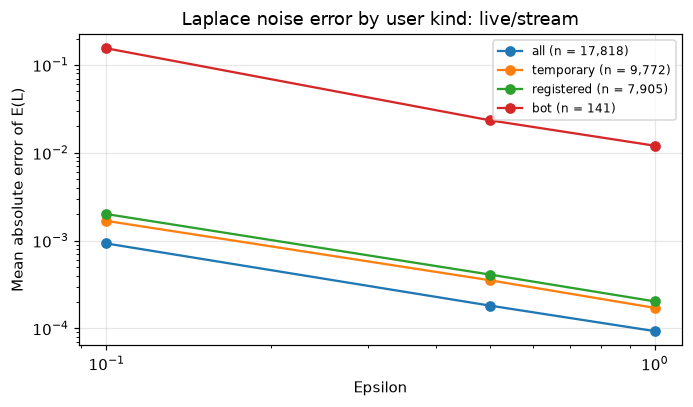

Saved: outputs\laplace\laplace_mae_by_user_kind.png


In [40]:
import matplotlib.pyplot as plt

live_stream = laplace_summary[
    (laplace_summary["cohort_id"] == "live")
    & (laplace_summary["label_source"] == "stream")
].copy()

fig, ax = plt.subplots(figsize=(6.4, 3.8), dpi=110)

for _, row in live_stream.iterrows():
    ax.plot(
        EPSILONS,
        [
            row[f"mae_eps_{epsilon}"]
            for epsilon in EPSILONS
        ],
        "o-",
        label=(
            f"{row['user_kind']} "
            f"(n = {int(row['eventual_reverts']):,})"
        ),
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Epsilon")
ax.set_ylabel("Mean absolute error of E(L)")
ax.set_title("Laplace noise error by user kind: live/stream")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()


plot_path = OUTPUT_DIR / "laplace_mae_by_user_kind.png"
plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)

 **Laplace Analysis 1** 

1. The error decreases for all user kinds as epsilon increases. The error ranking among the different user kinds remains generally consistent across the three epsilon values.

2. Laplace noise has a larger effect on smaller groups. In the live/stream series, the bot group has the largest error because it contains only 141 eventual reverts, while the all-editor group has much smaller error because it contains 17,818 eventual reverts.

3. Increasing epsilon reduces the error because it adds less noise. These results demonstrate the privacy–utility trade-off: smaller epsilon provides stronger privacy protection but produces larger errors.

## **5. Organizing & Analyzing the Summary Table** ##

This section creates a presentation-friendly version of the Laplace summary. The results are sorted by cohort, label source, and user kind so that related series appear together.

The sorting only changes the display order and does not change the analysis results.

In [28]:
view = laplace_summary.copy()

view["cohort_order"] = view["cohort_id"].map({
    "history": 0,
    "live": 1,
    "live_ext": 2,
})

view["source_order"] = view["label_source"].map({
    "dump": 0,
    "stream": 1,
})

view["kind_order"] = view["user_kind"].map({
    "all": 0,
    "temporary": 1,
    "registered": 2,
    "bot": 3,
    "unknown": 4,
})

view = (
    view.sort_values(
        ["cohort_order", "source_order", "kind_order"]
    )
    .drop(columns=["cohort_order", "source_order", "kind_order"])
    .reset_index(drop=True)
)

display(view)

,cohort_id,label_source,user_kind,eventual_reverts,mae_eps_0.1,p95_eps_0.1,mae_eps_0.5,p95_eps_0.5,mae_eps_1.0,p95_eps_1.0
0,history,dump,all,17646,0.000942,0.003320,0.000186,0.000651,0.000092,0.000330
1,history,dump,temporary,9863,0.001694,0.005859,0.000335,0.001198,0.000169,0.000602
2,history,dump,registered,7623,0.002061,0.006963,0.000418,0.001474,0.000204,0.000715
3,history,dump,bot,157,0.171987,0.552562,0.021101,0.074558,0.010557,0.037165
4,history,dump,unknown,3,11.494742,67.507216,2.243155,13.004931,0.997243,5.464868
5,live,dump,all,18077,0.000896,0.003106,0.000184,0.000623,0.000090,0.000312
6,live,dump,temporary,9881,0.001693,0.006072,0.000334,0.001186,0.000167,0.000573
7,live,dump,registered,8056,0.001996,0.006906,0.000419,0.001462,0.000203,0.000696
8,live,dump,bot,140,0.204427,0.666893,0.024604,0.084079,0.011546,0.041234
9,live,stream,all,17818,0.000927,0.003236,0.000182,0.000627,0.000093,0.000324


 **Laplace Analysis 2** 

1.The error is largest at epsilon = 0.1 and smallest at epsilon = 1.0.

2.Groups with larger sample sizes generally have smaller errors.

3.The all group has relatively small errors because it contains the largest number of eventual reverts.

4.The bot group has larger errors because its sample size is smaller.

5.The unknown group contains only three eventual reverts and therefore has extremely large errors. This suggests that very small groups should not be released with precise statistics.

6.The live_ext cohort has a much larger sample size, so its MAE and P95 errors are relatively low.

## **6.Saving Laplace Analysis Results and Metadata** ##

In [39]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

laplace_summary.to_csv(
    OUTPUT_DIR / "laplace_summary.csv",
    index=False,
)

view.to_csv(
    OUTPUT_DIR / "laplace_summary_grouped.csv",
    index=False,
)

metadata = {
    "input": str(INPUT_PATH),
    "analyzed_series": sorted(
        laplace_summary[
            ["cohort_id", "label_source"]
        ]
        .drop_duplicates()
        .apply(tuple, axis=1)
        .tolist()
    ),
    "epsilons": EPSILONS,
    "trials": TRIALS,
    "seed": SEED,
    "method": "Laplace noise on first-known wait-time histogram bins",
    "evaluated_waits": [
        "1 min",
        "5 min",
        "15 min",
        "1 h",
        "6 h",
        "1 d",
        "2 d",
    ],
}

with open(
    OUTPUT_DIR / "laplace_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(metadata, f, indent=2)



print("Saved:", OUTPUT_DIR / "laplace_summary.csv")
print("Saved:", OUTPUT_DIR / "laplace_summary_grouped.csv")
print("Saved:", OUTPUT_DIR / "laplace_metadata.json")



Saved: outputs\laplace\laplace_summary.csv
Saved: outputs\laplace\laplace_summary_grouped.csv
Saved: outputs\laplace\laplace_metadata.json
